### Importing libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from itables import show

### Importing data

In [2]:
items_processed = pd.read_csv("../data/items_data_processed/high_conf_items_processed_day.csv", sep=";", low_memory=False)
currency_processed = pd.read_csv("../data/currency_data_processed/currency_processed.csv", sep=";", low_memory=False)

# Currency Purchasing Power Index 
based on real life CPI: Consumer Price Index

In the early days of a league, many items are not yet traded or appear only later as players progress. This means that the item basket is incomplete on some days, especially at the beginning of the league. Because of this, normalising prices to the first day can produce misleading results. To avoid this problem, the index was calculated using a basket of currencies, which are available every day and actively traded from the start of the league.

### Currency basket

In [3]:
currency_basket = ["Divine Orb","Exalted Orb","Orb of Fusing","Orb of Alchemy","Chromatic Orb","Orb of Alteration","Sacred Orb","Glassblower's Bauble","Cartographer's Chisel","Stacked Deck" "Vaal Orb","Orb of Scouring","Gemcutter's Prism"]

In [4]:
# add the column "Day" indicates the day of the league

currency_processed["Date"] = pd.to_datetime(currency_processed["Date"])
currency_processed["Day"] = (currency_processed["Date"]- currency_processed.groupby("League")["Date"].transform("min")).dt.days + 1

#exporting dataset
currency_processed.reset_index(drop=True).to_csv("../data/currency_data_processed/currency_processed_day.csv",sep=";",index=False)

In [5]:
currency_processed.groupby("League")["Day"].max()

League
Affliction     110
Ancestor       110
Keepers        123
Mercenaries    137
Necropolis     117
Settlers       319
Name: Day, dtype: int64

In [6]:
# Select currency basket
currency_prices = currency_processed[currency_processed["Get"].isin(currency_basket)].copy()

Currencies in the basket have very different price levels.  **Divine Orb** cost usually hundreds of Chaos Orbs, while other currencies cost only a few Chaos or less than a Chaos. If we averaged the raw prices, expensive currencies would dominate the index and distort the results.

To avoid this, each currency is normalised to its price on the first day of the league. This transforms all currencies to a common relative scale, where the starting value equals 1. As a result, every currency contributes equally to the index, and the indicator reflects relative price changes over time rather than absolute price differences between currencies.

In [7]:
# Normalise each currency to its Day 1 price
currency_prices["Value_norm"] = (currency_prices["Value"] /currency_prices.groupby(["League", "Get"])["Value"].transform("first"))

In [8]:
# Currency CPI (mean of normalised prices per day)
curr_basket_price_per_day = (currency_prices.groupby(["League", "Day"])["Value_norm"].mean().reset_index(name="currency_index"))

#exporting dataset
curr_basket_price_per_day.reset_index(drop=True).to_csv("../data/currency_data_processed/currency_index.csv",sep=";",index=False)

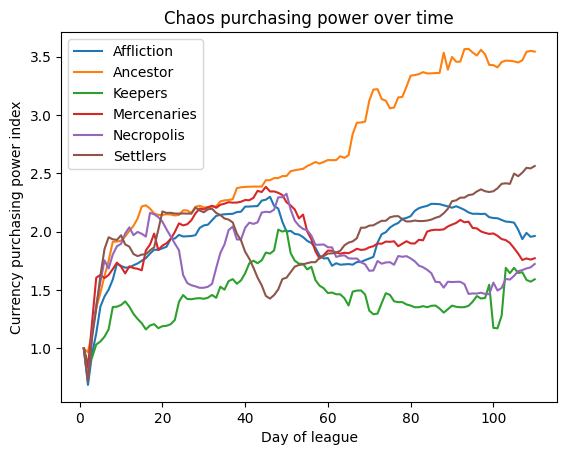

In [9]:
curr_basket_price_per_day110 = curr_basket_price_per_day[curr_basket_price_per_day["Day"] <= 110].copy()

for league, df_league in curr_basket_price_per_day110.groupby("League"):
    plt.plot(df_league["Day"],df_league["currency_index"],label=league)

plt.xlabel("Day of league")
plt.ylabel("Currency purchasing power index")
plt.title("Chaos purchasing power over time")
plt.legend()
plt.show()

**Conclusions:**

**1. Early-league inflation of Chaos Orbs**

Across all leagues, the first 10–20 days are characterised by a rapid increase in the Chaos Purchasing Power Index. Since the index measures the price of a basket of currencies relative to Chaos Orb, this increase indicates that more Chaos Orbs are required to purchase the same basket. In economic terms, this reflects a period of early-league inflation of Chaos Orb, when currency supply grows rapidly as players begin intensive farming activities.

**2. Strong and persistent inflation in the Ancestor league**

Among the analysed leagues, **Ancestor league** shows the most pronounced and persistent upward trend in the index. The value of the index increases steadily throughout the entire observed period, reaching values above 3.5. This indicates continuous inflation of Chaos Orbs during the league, meaning that Chaos Orb gradually lose purchasing power in the market.

**3. Mid-league deflation in several leagues**

In several leagues, including **Affliction**, **Mercenaries**, and **Necropolis**, the index begins to decline after approximately the middle of the league. This decrease indicates a period of deflation of Chaos Orb, during which Chaos Orb regain purchasing power. Such behaviour may reflect a gradual stabilisation of the market as the league progresses. As many players complete their main character builds, the demand for certain currencies used in crafting or trading may decrease, leading to lower relative prices of these currencies in terms of Chaos Orb.

**4. Temporary market disturbance in the Necropolis league**

A noticeable short-term decrease in the index occurs in the **Necropolis** league around days 25–35. This indicates a temporary increase in the purchasing power of Chaos Orb relative to other currencies. After this short period, the index resumes its previous trend. Such fluctuations may be associated with temporary shifts in player behaviour, changes in farming strategies, or short-term imbalances between supply and demand in the currency market.

**5. Different inflation patterns between leagues**

Although all leagues share a similar early adjustment phase, their longer-term behaviour differs significantly. Some leagues exhibit persistent inflation of Chaos Orb, while others transition into periods of stabilisation or partial deflation. These differences suggest that each league develops its own economic pattern, influenced not only by player behaviour and currency supply but also by changes introduced by the game developers during the league, such as balance updates or adjustments to game mechanics.